In [1]:
# Step I : Import Libraries
import tensorflow as tf
import matplotlib.pyplot as plt
import numpy as np 
from tensorflow.keras.utils import to_categorical

In [2]:
# Step II : Load the Dataset
with np.load("mnist.npz",allow_pickle=True) as data:
    x_train,y_train = data['x_train'],data['y_train']
    x_test,y_test = data['x_test'],data['y_test']
print(x_train.shape,y_train.shape)

(60000, 28, 28) (60000,)


In [3]:
# Step III : Preprocessing 

# normalize 
x_train = x_train.astype('float32')/255.0
x_test = x_test.astype('float32')/255.0

# reshape
x_train = x_train.reshape(-1,28,28,1)
x_test = x_test.reshape(-1,28,28,1)

# one hot encoding 
y_train = to_categorical(y_train,10)
y_test = to_categorical(y_test,10)

In [4]:
# Step IV : Data Augmentation
data_augmentation = tf.keras.Sequential([
    tf.keras.layers.RandomRotation(0.1),
    tf.keras.layers.RandomZoom(0.1)
])

In [6]:
# Step V : Model conf
model = tf.keras.Sequential([
    data_augmentation,

    # first conv layer
    tf.keras.layers.Conv2D(32,(3,3),activation='relu',input_shape=(28,28,1)),
    tf.keras.layers.MaxPooling2D((2,2)),

    #second conv layer
    tf.keras.layers.Conv2D(64,(3,3),activation='relu'),
    tf.keras.layers.MaxPooling2D((2,2)),

    tf.keras.layers.Flatten(),
    tf.keras.layers.Dense(128,activation='relu'),
    tf.keras.layers.Dense(10,activation='softmax')
])

In [7]:
# Step VI : Model Compilation
model.compile(
    optimizer='adam',
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

In [8]:
# Step VII : Training 
history = model.fit(
    x_train,
    y_train,
    epochs=2,
    batch_size=64,
    validation_split=0.2
)

Epoch 1/2
750/750 ━━━━━━━━━━━━━━━━━━━━ 25s 28ms/step - accuracy: 0.9086 - loss: 0.2967 - val_accuracy: 0.9690 - val_loss: 0.0975
Epoch 2/2
750/750 ━━━━━━━━━━━━━━━━━━━━ 20s 27ms/step - accuracy: 0.9668 - loss: 0.1065 - val_accuracy: 0.9809 - val_loss: 0.0651


In [9]:
# Step VIII : Evaluate
loss,accuracy = model.evaluate(x_test,y_test)
print(loss)
print(accuracy)

313/313 ━━━━━━━━━━━━━━━━━━━━ 2s 7ms/step - accuracy: 0.9804 - loss: 0.0580
0.05795843526721001
0.980400025844574


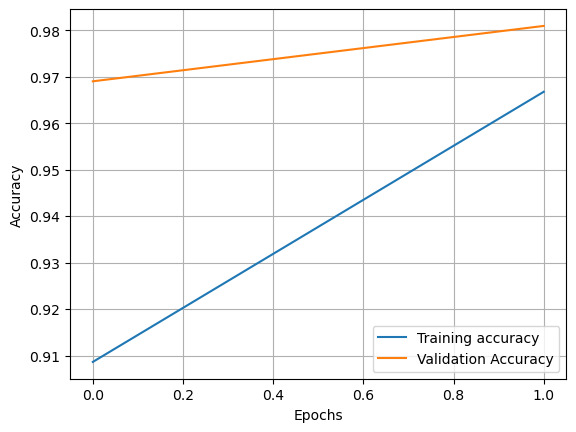

In [10]:
# Step IX : plotting
plt.plot(history.history['accuracy'],label='Training accuracy')
plt.plot(history.history['val_accuracy'],label='Validation Accuracy')
plt.xlabel("Epochs")
plt.ylabel("Accuracy")
plt.legend()
plt.grid()
plt.show()

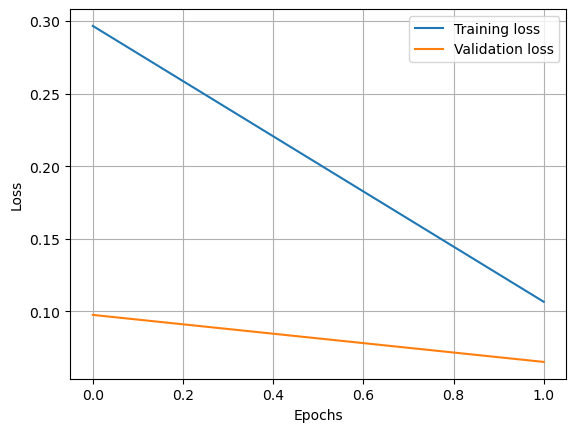

In [12]:
# Step IX : plotting
plt.plot(history.history['loss'],label='Training loss')
plt.plot(history.history['val_loss'],label='Validation loss')
plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.legend()
plt.grid()
plt.show()